#ev_mobile_2026.ipynb

Jarawadee Muenjak

---

Health Sciences, Medical Technology

##Initial Setting

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
path = "/content/drive/MyDrive/ev_pare/ev_mobile_2026_JM/"

##Image Classification

###Data Acquisition

In [ ]:
import os
import cv2

def loadimages(folder):
  images = []
  for filename in os.listdir(folder):
    img = cv2.imread(os.path.join(folder,filename))
    if img is not None:
      images.append(img)
  return images

In [ ]:
class0 = loadimages("/content/drive/MyDrive/ev_pare/01_crop_training/class0_artifact")
class1 = loadimages("/content/drive/MyDrive/ev_pare/01_crop_training/class1_evegg")

In [ ]:
print(f"class0 shape: {class0[0].shape}")
print(f"class1 shape: {class1[0].shape}")
print(f"num class0: {len(class0)}")
print(f"num class1: {len(class1)}")

class0 shape: (500, 500, 3)
class1 shape: (500, 500, 3)
num class0: 1415
num class1: 1415


In [ ]:
class0_label = [0] * len(class0)
class1_label = [1] * len(class1)

In [ ]:
from sklearn.model_selection import train_test_split

x_train_class0, x_test_class0, y_train_class0, y_test_class0 = train_test_split(class0, class0_label, test_size=0.2, random_state=8)
x_train_class1, x_test_class1, y_train_class1, y_test_class1 = train_test_split(class1, class1_label, test_size=0.2, random_state=8)

In [ ]:
x_train = x_train_class0 + x_train_class1
y_train = y_train_class0 + y_train_class1
x_test = x_test_class0 + x_test_class1
y_test = y_test_class0 + y_test_class1

In [ ]:
print(f"x_train: {len(x_train)}")
print(f"y_train: {len(y_train)}")
print(f"x_test: {len(x_test)}")
print(f"y_test: {len(y_test)}")

x_train: 2264
y_train: 2264
x_test: 566
y_test: 566


In [ ]:
for i in range(len(x_train)):
  x_train[i] = cv2.resize(x_train[i], (64,64), interpolation = cv2.INTER_AREA)

for i in range(len(x_test)):
  x_test[i] = cv2.resize(x_test[i], (64,64), interpolation = cv2.INTER_AREA)

In [ ]:
from keras.utils import to_categorical

y_train_cat = to_categorical(y_train)

###Image Augmentation Setting

In [ ]:
def imrotation(img,angle):
  (h, w) = img.shape[:2]
  center = (w // 2, h // 2)
  matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
  rotate_img = cv2.warpAffine(img, matrix, (w, h))
  return rotate_img[:,:,0:3]

In [ ]:
import numpy as np

def brightness(img, value):
  bright_matrix = np.ones(img.shape, dtype=img.dtype) * value
  brightened_image = cv2.add(img, bright_matrix)
  return brightened_image

In [ ]:
def histeq(img):
  image_yuv = cv2.cvtColor(img, cv2.COLOR_BGR2YUV)
  image_yuv[:,:,0] = cv2.equalizeHist(image_yuv[:,:,0])
  image = cv2.cvtColor(image_yuv, cv2.COLOR_YUV2BGR)
  return image

In [ ]:
def averaging(img):
  image = cv2.blur(img,(5,5))
  return image

In [ ]:
def addgaussian(img):
  b, g, r = cv2.split(img)

  mean = 0
  sd = 1

  b_noise = np.random.normal(mean, sd, b.shape).astype(np.uint8)
  g_noise = np.random.normal(mean, sd, g.shape).astype(np.uint8)
  r_noise = np.random.normal(mean, sd, r.shape).astype(np.uint8)

  b = cv2.add(b, b_noise)
  g = cv2.add(g, g_noise)
  r = cv2.add(r, r_noise)

  image = cv2.merge([b, g, r])
  return image

In [ ]:
def sharpening(img):
  kernel = np.array([[-1,-1,-1],[-1,9,-1],[-1,-1,-1]])
  image = cv2.filter2D(img, -1, kernel)
  return image

In [ ]:
def imageaugment(train_img, train_label):
  x_train_temp = []
  y_train_temp = []

  for idx in range(len(train_img)):
    for j in range(0, 360, 90):
      image_r = imrotation(train_img[idx], j)

      x_train_temp.append(image_r)
      y_train_temp.append(train_label[idx])

      x_train_temp.append(brightness(image_r, 50))
      y_train_temp.append(train_label[idx])

      x_train_temp.append(histeq(image_r))
      y_train_temp.append(train_label[idx])

      x_train_temp.append(averaging(image_r))
      y_train_temp.append(train_label[idx])

      x_train_temp.append(addgaussian(image_r))
      y_train_temp.append(train_label[idx])

      x_train_temp.append(sharpening(image_r))
      y_train_temp.append(train_label[idx])

  train_img = np.array(x_train_temp)
  train_label = np.array(y_train_temp)
  return train_img, train_label

In [ ]:
import numpy as np

x_train = np.array(x_train)
x_test = np.array(x_test)
y_train = np.array(y_train)
y_test = np.array(y_test)

###Cross-Validation Setting

In [ ]:
folding = 5
epoch_set = 100

In [ ]:
from keras.callbacks import Callback

class earlystopping_manual(Callback):
  def __init__(self, monitor='loss', value=0.001, verbose=1):
    super(Callback, self).__init__()
    self.monitor = monitor
    self.value = value
    self.verbose = verbose

  def on_epoch_end(self, epoch, logs={}):
    current = logs.get(self.monitor)
    if current < self.value:
      self.model.stop_training = True

In [ ]:
import cv2
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import numpy as np
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt

def perform_kfold(models):
  kf = KFold(n_splits=folding, shuffle=True, random_state=8)

  fold_acc = []
  fold_idx = 1

  full_x_train = x_train
  full_y_train_cat = y_train_cat

  for train_ind, test_ind in kf.split(full_x_train):
    x_train_fold = full_x_train[train_ind]
    x_test_fold = full_x_train[test_ind]
    y_train_fold = full_y_train_cat[train_ind]
    y_test_fold = full_y_train_cat[test_ind]

    #---------------------------------------------------------------------
    x_train_fold, y_train_fold = imageaugment(x_train_fold, y_train_fold)
    #---------------------------------------------------------------------

    model = models

    cond = [earlystopping_manual(monitor='loss', value=0.001, verbose=1)]
    history = model.fit(x_train_fold, y_train_fold, epochs=epoch_set, validation_data=(x_test_fold, y_test_fold), callbacks=cond)

    plt.figure(figsize=(10, 10))
    plt.subplot(5, 1, fold_idx)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.ylim([0, 1])
    plt.legend(loc='upper left')
    plt.grid(True)

    fold_idx += 1

    y_pred = model.predict(x_test_fold)
    y_pred = np.argmax(y_pred, axis=1)
    y_true_test_labels = np.argmax(y_test_fold, axis=1)

    print('Confusion Matrix:')
    print(confusion_matrix(y_true_test_labels, y_pred))
    print('--------------------------')
    print("Accuracy:", accuracy_score(y_true_test_labels, y_pred))
    print("Precision:", precision_score(y_true_test_labels, y_pred, average='weighted'))
    print("Recall:", recall_score(y_true_test_labels, y_pred, average='weighted'))
    print("F1 score:", f1_score(y_true_test_labels, y_pred, average='weighted'))

    acc = accuracy_score(y_true_test_labels, y_pred)
    fold_acc.append(acc)

  plt.plot(fold_acc, label='Accuracy')
  plt.xlabel('Folding')
  plt.ylabel('Accuracy')
  plt.ylim([0, 2])
  plt.legend(loc='lower right')
  plt.grid(True)

  print("Mean accuracy: {:.2f}".format(np.mean(fold_acc)))
  print("Standard deviation: {:.2f}".format(np.std(fold_acc)))
  print("Individual fold accuracies:", fold_acc)

###Model Test Setting

In [ ]:
import matplotlib.pyplot as plt

def modeltesting(history):
  plt.figure()
  plt.plot(history.history['loss'], label='Loss Function')
  plt.plot(history.history['val_loss'], label='Validation loss')
  plt.xlabel('Epoch')
  plt.ylabel('Loss')
  plt.ylim([0, 1])
  plt.legend(loc='upper left')

  plt.figure()
  plt.plot(history.history['accuracy'], label='Accuracy')
  plt.plot(history.history['val_accuracy'], label='Validation accuracy')
  plt.xlabel('Epoch')
  plt.ylabel('Accuracy')
  plt.ylim([0, 1])
  plt.legend(loc='lower right')

  y_outp = model.predict(x_test)
  y_pred = np.argmax(y_outp, axis=1)

  from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

  print('Confusion Matrix:')
  print(confusion_matrix(y_test, y_pred))
  print('--------------------------')
  print("Accuracy:", accuracy_score(y_test, y_pred))
  print("Precision:", precision_score(y_test, y_pred, average='weighted'))
  print("Recall:", recall_score(y_test, y_pred, average='weighted'))
  print("F1 score:", f1_score(y_test, y_pred, average='weighted'))

  from sklearn.metrics import roc_curve, auc

  fpr, tpr, thresholds = roc_curve(y_test, y_pred)
  roc_auc = auc(fpr, tpr)

  plt.figure()
  plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
  plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
  plt.xlim([0.0, 1.0])
  plt.ylim([0.0, 1.05])
  plt.xlabel('False Positive Rate')
  plt.ylabel('True Positive Rate')
  plt.title('Receiver Operating Characteristic Curve')
  plt.legend(loc="lower right")
  plt.show()

###Model Structure

In [ ]:
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

def cnn():
  model = Sequential()
  model = Sequential()

  model.add(Conv2D(32, (3, 3), activation = 'relu', input_shape = (x_train[0].shape)))
  model.add(Conv2D(32, (3, 3), activation = 'relu'))
  model.add(Conv2D(32, (3, 3), activation = 'relu'))
  model.add(MaxPooling2D((2, 2)))
  model.add(Conv2D(16, (3, 3), activation = 'relu'))
  model.add(Conv2D(16, (3, 3), activation = 'relu'))
  model.add(Conv2D(16, (3, 3), activation = 'relu'))
  model.add(MaxPooling2D((2, 2)))
  model.add(Conv2D(8, (3, 3), activation = 'relu'))
  model.add(Conv2D(8, (3, 3), activation = 'relu'))
  model.add(Conv2D(8, (3, 3), activation = 'relu'))
  model.add(MaxPooling2D((2, 2)))
  model.add(Flatten())
  model.add(Dense(64, activation = 'relu'))
  model.add(Dense(128, activation = 'relu'))
  model.add(Dense(64, activation = 'relu'))
  model.add(Dense(32, activation = 'relu'))
  model.add(Dense(2, activation = 'sigmoid'))

  model.compile(optimizer = 'sgd', loss = 'mse', metrics = ['accuracy'])
  return model

In [ ]:
from keras.applications import ResNet50

def resnet50():
  model = ResNet50(weights=None, include_top=True, input_shape = x_train[0].shape, classes=2)
  model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
  return model

In [ ]:
from keras.applications.mobilenet import MobileNet

def mobilenet():
  model = MobileNet(input_shape = x_train[0].shape, include_top = True, weights = None, classes = 2)
  model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
  return model

In [ ]:
from keras.applications import DenseNet121

def densenet121():
  model = DenseNet121(weights=None, include_top=True, input_shape=x_train[0].shape, classes=2)
  model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
  return model

###Perform K-Fold Cross Validation

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 35s 14ms/step - accuracy: 0.6754 - loss: 0.2043 - val_accuracy: 0.8168 - val_loss: 0.1394
Epoch 2/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8284 - loss: 0.1254 - val_accuracy: 0.7925 - val_loss: 0.1593
Epoch 3/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8768 - loss: 0.0920 - val_accuracy: 0.8874 - val_loss: 0.0774
Epoch 4/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9044 - loss: 0.0741 - val_accuracy: 0.9139 - val_loss: 0.0609
Epoch 5/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9195 - loss: 0.0620 - val_accuracy: 0.7439 - val_loss: 0.1871
Epoch 6/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9295 - loss: 0.0549 - val_accuracy: 0.9360 - val_loss: 0.0456
Epoch 7/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9390 - loss: 0.0480 - val_accuracy: 0.9205 - val_loss: 0.0606
Epoch 8/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9464 - loss:

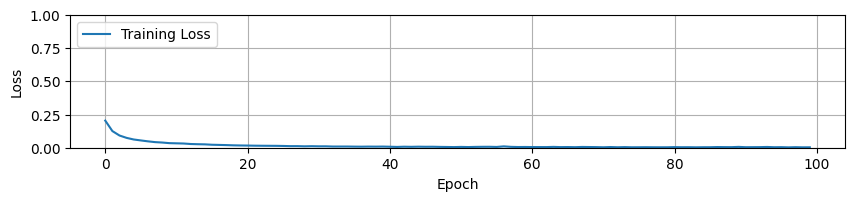

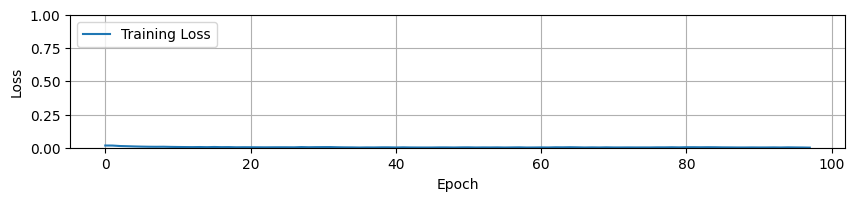

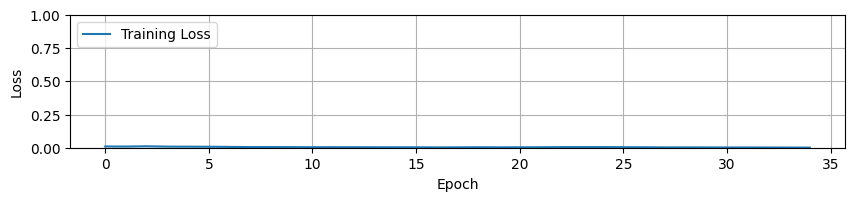

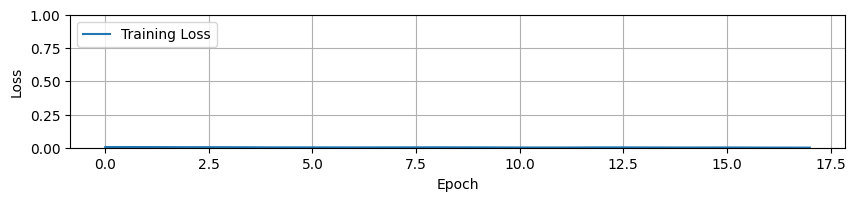

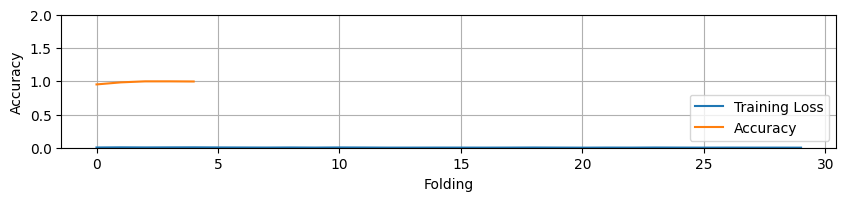

In [ ]:
perform_kfold(cnn())

Epoch 1/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 123s 45ms/step - accuracy: 0.7686 - loss: 0.5559 - val_accuracy: 0.6976 - val_loss: 0.5670
Epoch 2/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 23s 17ms/step - accuracy: 0.9503 - loss: 0.1340 - val_accuracy: 0.8985 - val_loss: 0.2947
Epoch 3/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 23s 17ms/step - accuracy: 0.9740 - loss: 0.0723 - val_accuracy: 0.8455 - val_loss: 0.4326
Epoch 4/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 23s 17ms/step - accuracy: 0.9802 - loss: 0.0578 - val_accuracy: 0.9051 - val_loss: 0.2649
Epoch 5/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 23s 17ms/step - accuracy: 0.9867 - loss: 0.0385 - val_accuracy: 0.8057 - val_loss: 0.5422
Epoch 6/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 23s 17ms/step - accuracy: 0.9890 - loss: 0.0316 - val_accuracy: 0.9868 - val_loss: 0.0373
Epoch 7/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 23s 17ms/step - accuracy: 0.9914 - loss: 0.0261 - val_accuracy: 0.8985 - val_loss: 0.2760
Epoch 8/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 23s 17ms/step - accuracy:

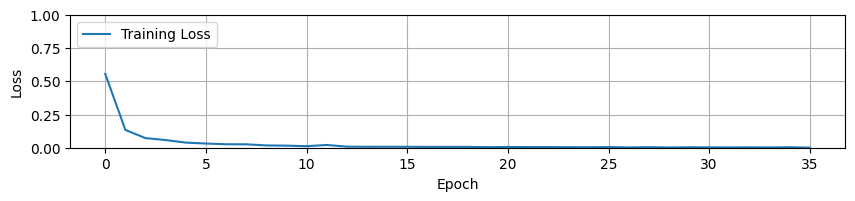

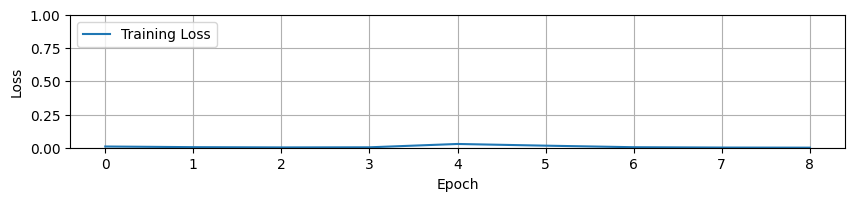

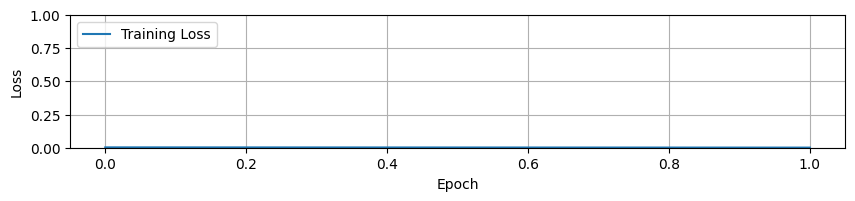

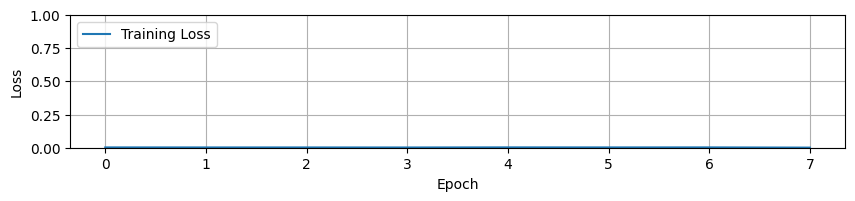

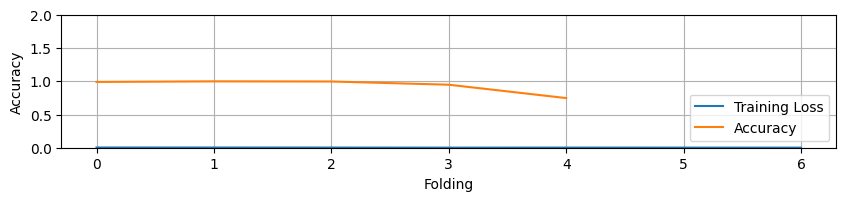

In [ ]:
perform_kfold(resnet50())

Epoch 1/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 58s 22ms/step - accuracy: 0.7707 - loss: 0.4662 - val_accuracy: 0.8985 - val_loss: 0.2362
Epoch 2/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.9289 - loss: 0.1812 - val_accuracy: 0.8764 - val_loss: 0.3888
Epoch 3/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.9711 - loss: 0.0792 - val_accuracy: 0.9514 - val_loss: 0.1097
Epoch 4/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.9841 - loss: 0.0461 - val_accuracy: 0.9845 - val_loss: 0.0445
Epoch 5/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.9876 - loss: 0.0368 - val_accuracy: 0.9890 - val_loss: 0.0339
Epoch 6/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.9903 - loss: 0.0292 - val_accuracy: 0.9735 - val_loss: 0.0975
Epoch 7/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9923 - loss: 0.0238 - val_accuracy: 0.9779 - val_loss: 0.0828
Epoch 8/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.9936 - lo

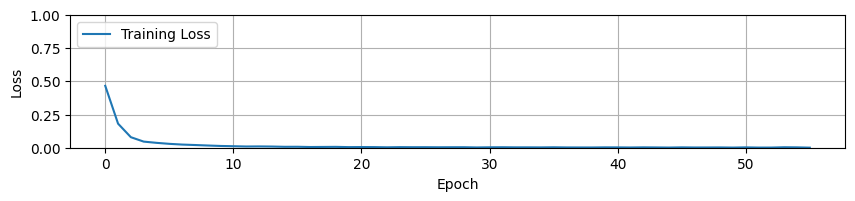

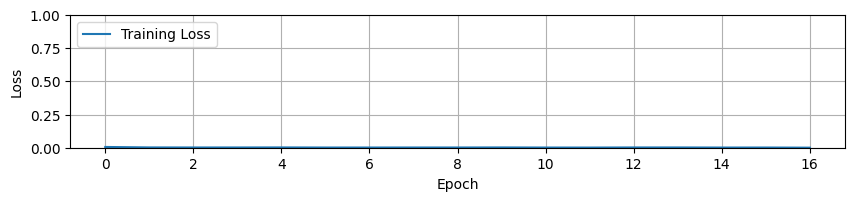

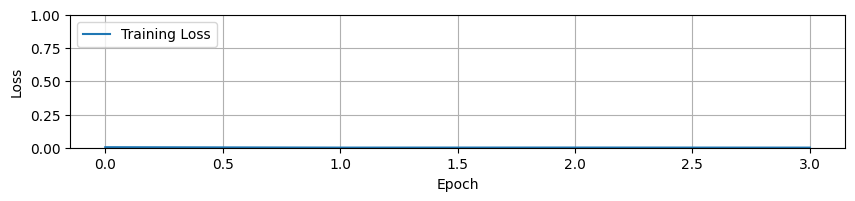

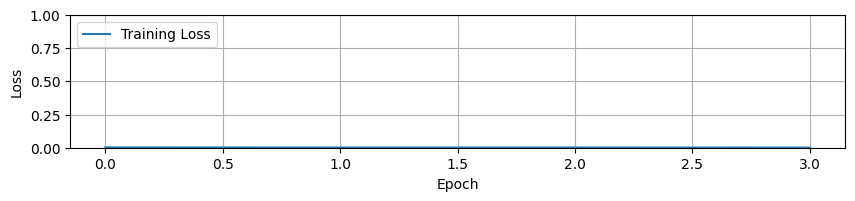

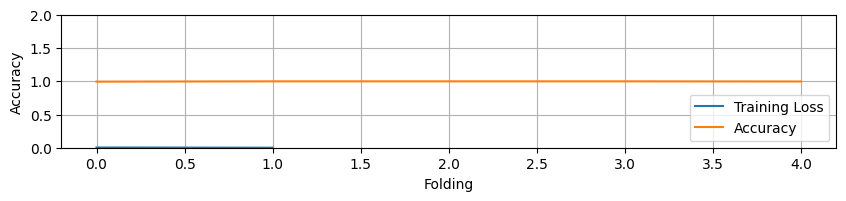

In [ ]:
perform_kfold(mobilenet())

Epoch 1/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 365s 139ms/step - accuracy: 0.7846 - loss: 0.4469 - val_accuracy: 0.5519 - val_loss: 0.7797
Epoch 2/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 35s 26ms/step - accuracy: 0.9434 - loss: 0.1428 - val_accuracy: 0.5453 - val_loss: 2.0634
Epoch 3/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 37s 27ms/step - accuracy: 0.9812 - loss: 0.0542 - val_accuracy: 0.9514 - val_loss: 0.1206
Epoch 4/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 37s 27ms/step - accuracy: 0.9877 - loss: 0.0343 - val_accuracy: 0.8521 - val_loss: 0.3527
Epoch 5/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 38s 28ms/step - accuracy: 0.9895 - loss: 0.0303 - val_accuracy: 0.9625 - val_loss: 0.1203
Epoch 6/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 37s 27ms/step - accuracy: 0.9925 - loss: 0.0225 - val_accuracy: 0.8896 - val_loss: 0.3479
Epoch 7/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 39s 28ms/step - accuracy: 0.9937 - loss: 0.0173 - val_accuracy: 0.9713 - val_loss: 0.1106
Epoch 8/100
1359/1359 ━━━━━━━━━━━━━━━━━━━━ 40s 29ms/step - accuracy

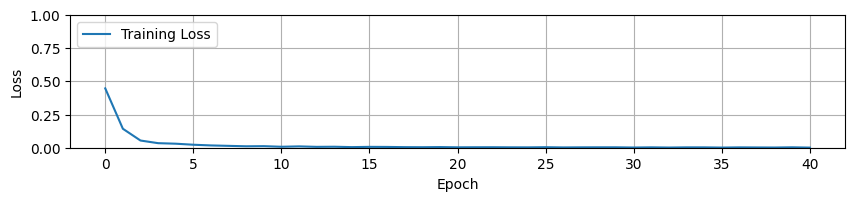

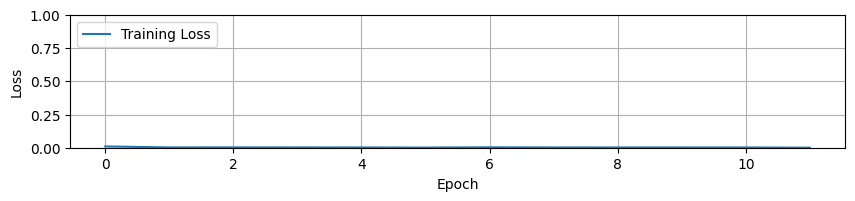

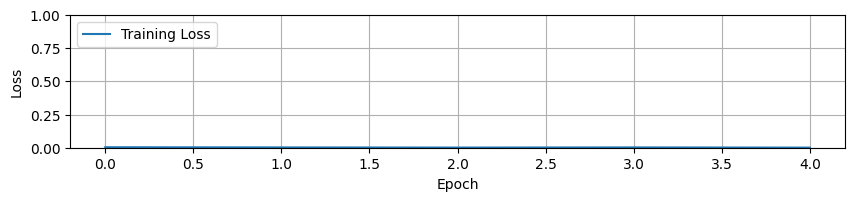

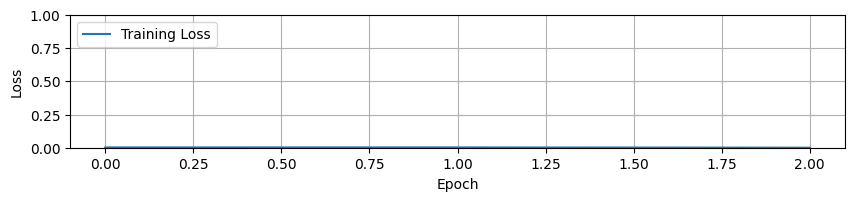

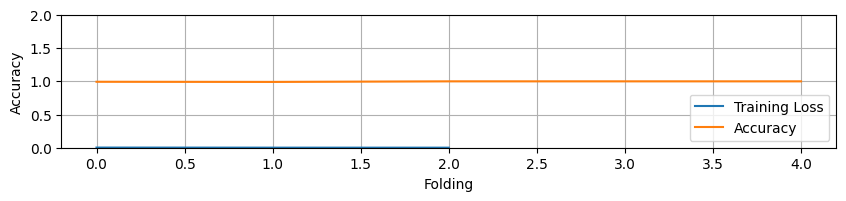

In [ ]:
perform_kfold(densenet121())

###Model Training and Testing

Data augmentation

In [ ]:
x_train, y_train_cat = imageaugment(x_train, y_train_cat)

Model: cnn

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 52s 63ms/step - accuracy: 0.6274 - loss: 0.2334 - val_accuracy: 0.1110 - val_loss: 0.4193
Epoch 2/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6709 - loss: 0.2125 - val_accuracy: 0.6438 - val_loss: 0.2019
Epoch 3/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7373 - loss: 0.1792 - val_accuracy: 0.5531 - val_loss: 0.2719
Epoch 4/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7926 - loss: 0.1461 - val_accuracy: 0.6907 - val_loss: 0.2077
Epoch 5/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8376 - loss: 0.1180 - val_accuracy: 0.8002 - val_loss: 0.1391
Epoch 6/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8645 - loss: 0.0999 - val_accuracy: 0.8695 - val_loss: 0.0955
Epoch 7/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8880 - loss: 0.0842 - val_accuracy: 0.8155 - val_loss: 0.1369
Epoch 8/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9031 - loss: 0.0735 - val_ac

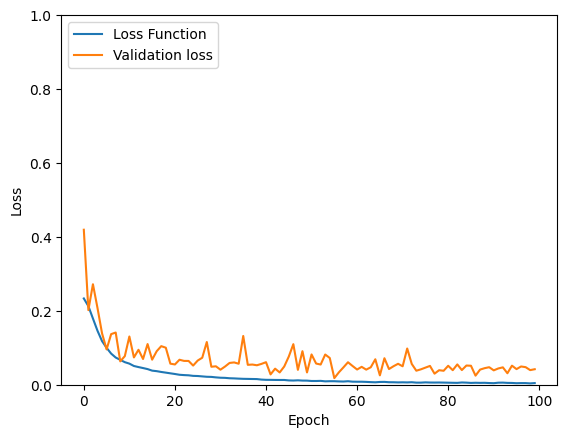

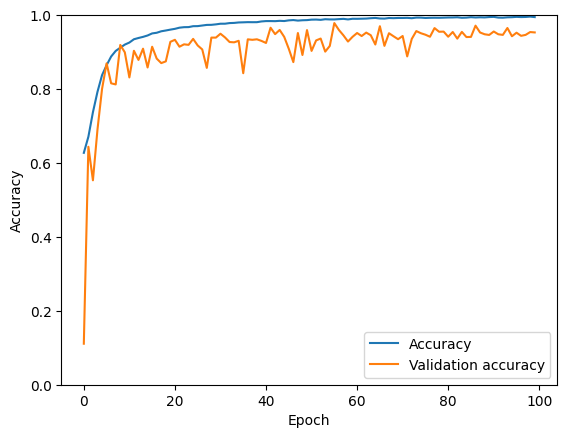

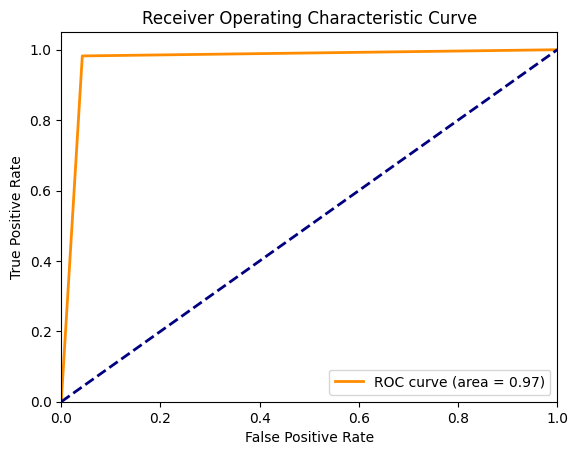

In [ ]:
model = cnn()
history = model.fit(x_train, y_train_cat, epochs = 100, batch_size = 100, validation_split = 0.2)
training(history)
testing()

In [ ]:
model.save(path + "ev_cnn.keras")

Model: resnet50

Epoch 1/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 114s 116ms/step - accuracy: 0.8391 - loss: 0.4297 - val_accuracy: 0.7476 - val_loss: 0.6231
Epoch 2/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - accuracy: 0.9450 - loss: 0.1571 - val_accuracy: 0.8341 - val_loss: 0.4757
Epoch 3/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.9763 - loss: 0.0655 - val_accuracy: 0.2149 - val_loss: 3.8042
Epoch 4/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - accuracy: 0.9853 - loss: 0.0411 - val_accuracy: 0.6568 - val_loss: 1.7432
Epoch 5/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.9898 - loss: 0.0294 - val_accuracy: 0.5533 - val_loss: 2.4408
Epoch 6/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.9934 - loss: 0.0192 - val_accuracy: 0.7316 - val_loss: 1.0209
Epoch 7/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.9935 - loss: 0.0202 - val_accuracy: 0.6690 - val_loss: 1.7948
Epoch 8/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.9939 - loss:

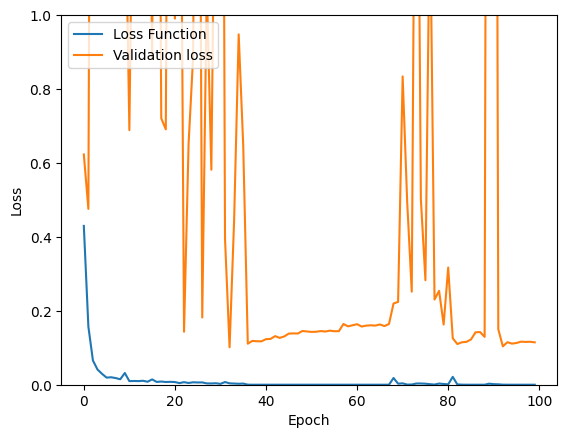

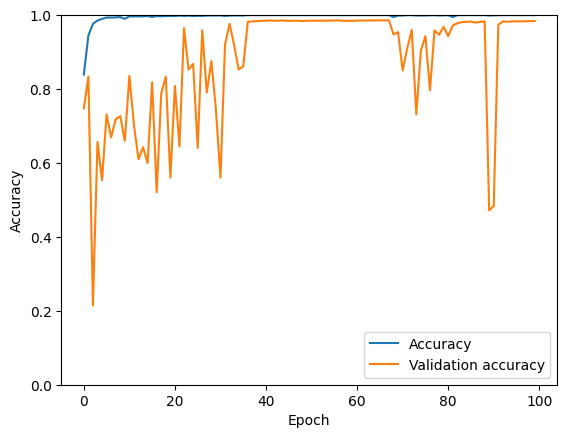

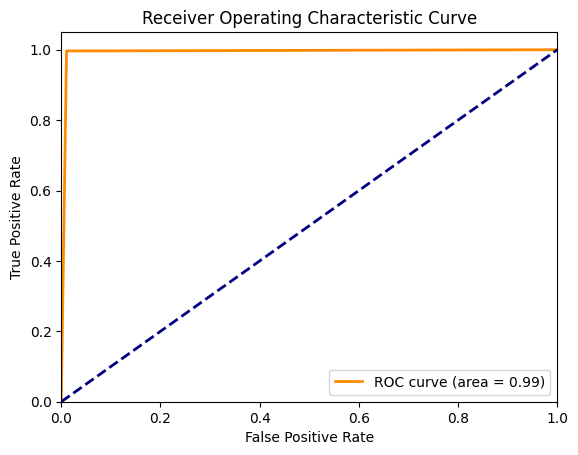

In [ ]:
model = resnet50()
history = model.fit(x_train, y_train_cat, epochs = 100, batch_size = 100, validation_split = 0.2)
training(history)
testing()

In [ ]:
model.save(path + "ev_resnet50.keras")

Model: mobilenet

Epoch 1/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 65s 68ms/step - accuracy: 0.7645 - loss: 0.4813 - val_accuracy: 0.0000e+00 - val_loss: 2.4031
Epoch 2/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8840 - loss: 0.2731 - val_accuracy: 0.6342 - val_loss: 0.9086
Epoch 3/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9336 - loss: 0.1664 - val_accuracy: 0.8890 - val_loss: 0.3116
Epoch 4/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9613 - loss: 0.1005 - val_accuracy: 0.8675 - val_loss: 0.4067
Epoch 5/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9758 - loss: 0.0654 - val_accuracy: 0.9314 - val_loss: 0.1786
Epoch 6/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9840 - loss: 0.0447 - val_accuracy: 0.9460 - val_loss: 0.1707
Epoch 7/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9880 - loss: 0.0332 - val_accuracy: 0.8896 - val_loss: 0.4325
Epoch 8/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9908 - loss: 0.02

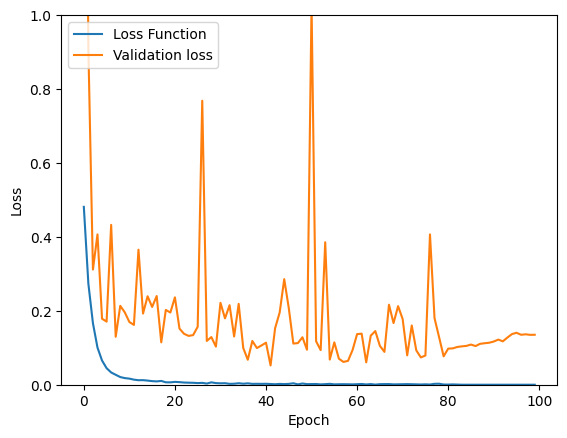

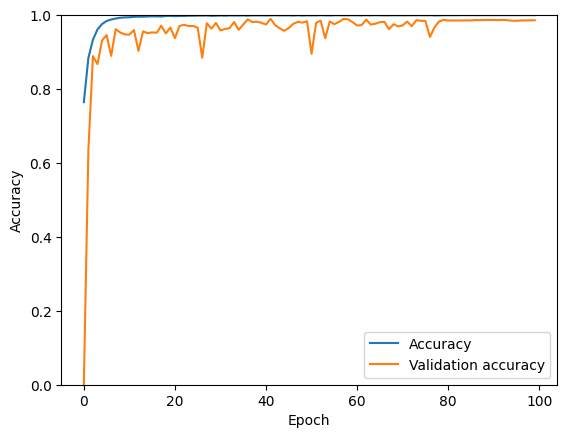

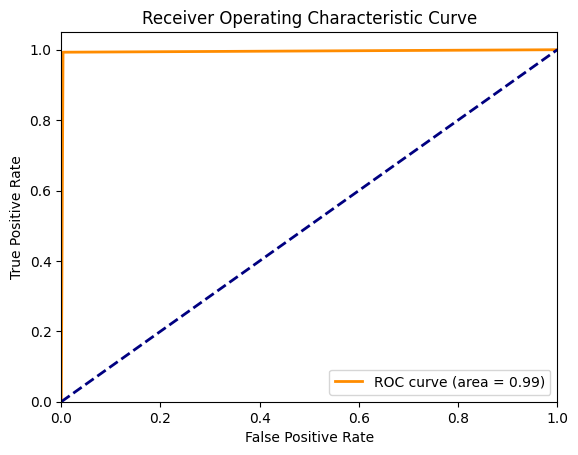

In [ ]:
model = mobilenet()
history = model.fit(x_train, y_train_cat, epochs = 100, batch_size = 100, validation_split = 0.2)
training(history)
testing()

In [ ]:
model.save(path + "ev_mobilenet.keras")

Model: densenet121

Epoch 1/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 337s 362ms/step - accuracy: 0.8284 - loss: 0.3792 - val_accuracy: 0.2934 - val_loss: 5.1469
Epoch 2/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 15s 35ms/step - accuracy: 0.9262 - loss: 0.1797 - val_accuracy: 0.3458 - val_loss: 2.2298
Epoch 3/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 15s 35ms/step - accuracy: 0.9730 - loss: 0.0742 - val_accuracy: 0.3292 - val_loss: 6.2024
Epoch 4/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 15s 35ms/step - accuracy: 0.9861 - loss: 0.0413 - val_accuracy: 0.2620 - val_loss: 8.9175
Epoch 5/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 15s 35ms/step - accuracy: 0.9895 - loss: 0.0282 - val_accuracy: 0.5907 - val_loss: 2.5791
Epoch 6/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 15s 35ms/step - accuracy: 0.9933 - loss: 0.0199 - val_accuracy: 0.7715 - val_loss: 1.1082
Epoch 7/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 15s 35ms/step - accuracy: 0.9938 - loss: 0.0177 - val_accuracy: 0.7814 - val_loss: 0.9071
Epoch 8/100
435/435 ━━━━━━━━━━━━━━━━━━━━ 15s 35ms/step - accuracy: 0.9949 - loss:

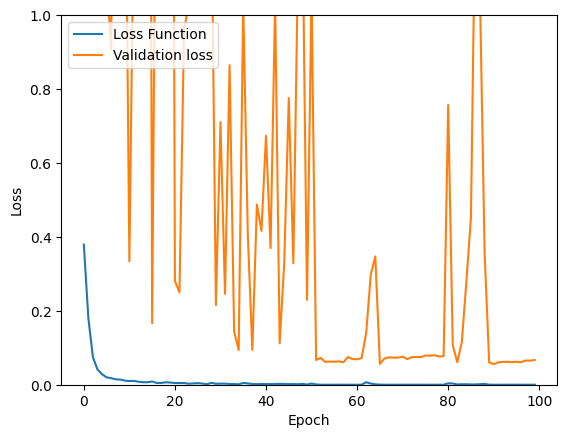

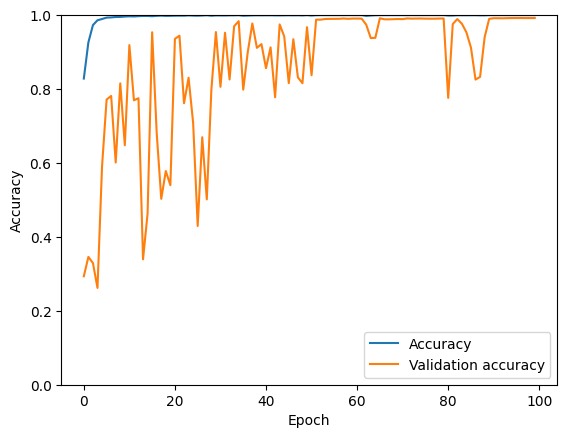

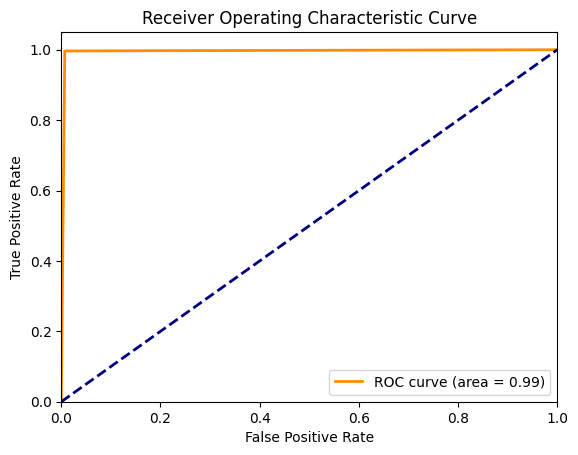

In [ ]:
model = densenet121()
history = model.fit(x_train, y_train_cat, epochs = 100, batch_size = 100, validation_split = 0.2)
training(history)
testing()

In [ ]:
model.save(path + "ev_densenet121.keras")

##Object Detection

###Perpare for Object Detection

In [ ]:
import cv2
import numpy as np
from keras.models import load_model
from keras.losses import mean_squared_error

model_path = "/content/drive/MyDrive/ev_pare/ev_mobile_2026_PP/ev_mobilenet.keras"
class_label = ["Artifact", "Ev eggs"]

def mse(y_true, y_pred):
  return mean_squared_error(y_true, y_pred)

model = load_model(model_path, custom_objects={'mse': mse})

def drawbox(img, label, a, b, c, d, color):
  image = cv2.rectangle(img, (c, a), (d, b), color, 2)
  image = cv2.putText(image, label, (c, a - 10), cv2.FONT_HERSHEY_TRIPLEX, 0.8, color, 2)
  return image

def compute_iou(box1, box2):
  y1 = max(box1[0], box2[0])
  y2 = min(box1[1], box2[1])
  x1 = max(box1[2], box2[2])
  x2 = min(box1[3], box2[3])
  inter_w = max(0, x2 - x1)
  inter_h = max(0, y2 - y1)
  inter_area = inter_w * inter_h
  box1_area = (box1[1] - box1[0]) * (box1[3] - box1[2])
  box2_area = (box2[1] - box2[0]) * (box2[3] - box2[2])
  union_area = box1_area + box2_area - inter_area
  if union_area == 0:
    return 0
  return inter_area / union_area

def nms(detections, iou_threshold):
  nms_dets = []
  for class_idx in set([d['class_idx'] for d in detections]):
    class_dets = [d for d in detections if d['class_idx'] == class_idx]
    class_dets = sorted(class_dets, key=lambda x: x['score'], reverse=True)
    keep = []
    while class_dets:
      curr = class_dets.pop(0)
      keep.append(curr)
      class_dets = [
        d for d in class_dets
        if compute_iou(curr['bbox'], d['bbox']) < iou_threshold
      ]
    nms_dets.extend(keep)
  return nms_dets

def merge_connected_boxes_by_class(detections, merge_iou_threshold):
  merged = []
  for class_idx in set([d['class_idx'] for d in detections]):
    class_dets = [d for d in detections if d['class_idx'] == class_idx]
    used = set()
    groups = []
    for i, det in enumerate(class_dets):
      if i in used:
        continue
      group = [det]
      used.add(i)
      changed = True
      while changed:
        changed = False
        for j, other in enumerate(class_dets):
          if j in used:
            continue
          if any(compute_iou(d['bbox'], other['bbox']) > merge_iou_threshold for d in group):
            group.append(other)
            used.add(j)
            changed = True
      groups.append(group)
    for group in groups:
      tops = [d['bbox'][0] for d in group]
      bottoms = [d['bbox'][1] for d in group]
      lefts = [d['bbox'][2] for d in group]
      rights = [d['bbox'][3] for d in group]
      merged_box = [min(tops), max(bottoms), min(lefts), max(rights)]
      max_score = max(d['score'] for d in group)
      merged.append({"bbox": merged_box, "class_idx": class_idx, "score": max_score})
  return merged

###Perform for All Images

In [ ]:
import os
import cv2
import numpy as np

input_dir = "/content/drive/MyDrive/ev_pare/02_object_detection"
output_dir =  "/content/drive/MyDrive/ev_pare/ev_mobile_2026_JM/objectdetectionimages"

if not os.path.exists(output_dir):
    os.makedirs(output_dir)

def ObjectDet_with_boxes(filepath, threshold, nms_threshold, merge_iou_threshold):
  img = cv2.imread(filepath)
  if img is None:
      return None, []

  box_size_y, box_size_x, step_size = 500, 500, 50
  resize_input_y, resize_input_x = 64, 64
  img_h, img_w = img.shape[:2]

  coords = []
  patches = []
  for i in range(0, img_h - box_size_y + 1, step_size):
    for j in range(0, img_w - box_size_x + 1, step_size):
      img_patch = img[i:i+box_size_y, j:j+box_size_x]
      brightness = np.mean(cv2.cvtColor(img_patch, cv2.COLOR_BGR2GRAY))
      if brightness < 50:
        continue
      img_patch = cv2.resize(img_patch, (resize_input_y, resize_input_x), interpolation=cv2.INTER_AREA)
      patches.append(img_patch)
      coords.append((i, j))

  if len(patches) == 0:
      return img, []

  patches = np.array(patches)
  y_out = model.predict(patches, batch_size=64, verbose=0)
  detections = []
  for idx, pred in enumerate(y_out):
    for class_idx in range(len(class_label)):
      score = pred[class_idx]
      if score > threshold and class_idx != 0:
        a, c = coords[idx]
        b, d = a + box_size_y, c + box_size_x
        detections.append({"bbox": [a, b, c, d], "score": float(score), "class_idx": class_idx})

  nms_detections = nms(detections, iou_threshold=nms_threshold)
  if merge_iou_threshold is not None and merge_iou_threshold > 0:
    merged_detections = merge_connected_boxes_by_class(nms_detections, merge_iou_threshold=merge_iou_threshold)
  else:
    merged_detections = nms_detections

  img_output = img.copy()
  colors = [(0,255,0), (255,0,0), (0,0,255), (0,255,255), (255,0,255), (255,255,0)]
  for det in merged_detections:
    a, b, c, d = det['bbox']
    class_idx = det['class_idx']
    label = f"{class_label[class_idx]}: {det['score']:.2f}"
    color = colors[class_idx % len(colors)]
    img_output = drawbox(img_output, label, a, b, c, d, color)
  return img_output, merged_detections

for filename in os.listdir(input_dir):
  if filename.lower().endswith(('.png', '.jpg', '.jpeg', '.tif', '.tiff')):
    filepath = os.path.join(input_dir, filename)
    print(f"Processing {filename}...")
    img_output, dets = ObjectDet_with_boxes(
        filepath,
        threshold=0.95,
        nms_threshold=0.3,
        merge_iou_threshold=0.3)

    if img_output is not None:
      box_strs = []
      for d in dets:
        a, b, c, d_box = d['bbox']
        box_strs.append(f"{a}_{b}_{c}_{d_box}")

      name, ext = os.path.splitext(filename)
      if box_strs:
        new_filename = f"{name}_boxes_{'-'.join(box_strs)}{ext}"
      else:
        new_filename = f"{name}_no_boxes{ext}"

      out_filepath = os.path.join(output_dir, new_filename)
      cv2.imwrite(out_filepath, img_output)
      print(f"Saved to {out_filepath}")

Processing IMG_20250610_140113.jpg...
Saved to /content/drive/MyDrive/ev_pare/ev_mobile_2026_JM/objectdetectionimages/IMG_20250610_140113_boxes_1950_2450_1250_1750.jpg
Processing IMG_20250610_140529.jpg...
Saved to /content/drive/MyDrive/ev_pare/ev_mobile_2026_JM/objectdetectionimages/IMG_20250610_140529_boxes_2050_2550_1250_1750.jpg
Processing IMG_20250610_141500.jpg...
Saved to /content/drive/MyDrive/ev_pare/ev_mobile_2026_JM/objectdetectionimages/IMG_20250610_141500_boxes_1950_2450_1300_1800.jpg
Processing IMG_20250610_141811.jpg...
Saved to /content/drive/MyDrive/ev_pare/ev_mobile_2026_JM/objectdetectionimages/IMG_20250610_141811_boxes_2000_2500_1150_1650-2250_2750_1500_2000.jpg
Processing IMG_20250610_142612.jpg...
Saved to /content/drive/MyDrive/ev_pare/ev_mobile_2026_JM/objectdetectionimages/IMG_20250610_142612_boxes_1950_2450_1450_1950.jpg
Processing IMG_20250610_142903.jpg...
Saved to /content/drive/MyDrive/ev_pare/ev_mobile_2026_JM/objectdetectionimages/IMG_20250610_142903_bo

###Calculate (mean) Average Precision (@0.5, @0.5:0.95:0.05)

In [ ]:
import os
import cv2
import numpy as np
from collections import defaultdict

expert_dir = "/content/drive/MyDrive/ev_pare/03_boundingbox_expert"
pred_dir = "/content/drive/MyDrive/ev_pare/ev_mobile_2026_JM/objectdetectionimages"

def extract_red_boxes(filepath):
  img = cv2.imread(filepath)
  if img is None:
    return []
  lower_red = np.array([0, 0, 200])
  upper_red = np.array([50, 50, 255])
  mask = cv2.inRange(img, lower_red, upper_red)

  contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
  gt_boxes = []
  for cnt in contours:
    x, y, w, h = cv2.boundingRect(cnt)
    if w > 10 and h > 10:
      gt_boxes.append([y, y+h, x, x+w])
  return gt_boxes

def parse_pred_boxes(filename):
  name, ext = os.path.splitext(filename)
  if "_no_boxes" in name:
    return []

  boxes_str = name.split("_boxes_")[-1]
  if not boxes_str:
    return []

  pred_boxes = []
  box_items = boxes_str.split("-")
  for item in box_items:
    parts = item.split("_")
    if len(parts) == 4:
      try:
        pred_boxes.append([int(parts[0]), int(parts[1]), int(parts[2]), int(parts[3])])
      except ValueError:
        continue
  return pred_boxes

def compute_iou(box1, box2):
  y1 = max(box1[0], box2[0])
  y2 = min(box1[1], box2[1])
  x1 = max(box1[2], box2[2])
  x2 = min(box1[3], box2[3])
  inter_w = max(0, x2 - x1)
  inter_h = max(0, y2 - y1)
  inter_area = inter_w * inter_h

  box1_area = (box1[1] - box1[0]) * (box1[3] - box1[2])
  box2_area = (box2[1] - box2[0]) * (box2[3] - box2[2])
  union_area = box1_area + box2_area - inter_area

  if union_area == 0:
    return 0
  return inter_area / union_area

def calculate_ap(gt_boxes_all, pred_boxes_all, iou_threshold):
  tp = 0
  fp = 0
  total_gt = 0

  for img_name in gt_boxes_all.keys():
    gt_boxes = gt_boxes_all[img_name]
    pred_boxes = pred_boxes_all.get(img_name, [])
    total_gt += len(gt_boxes)

    matched_gt = set()
    for p_box in pred_boxes:
      best_iou = 0
      best_gt_idx = -1
      for i, g_box in enumerate(gt_boxes):
        iou = compute_iou(p_box, g_box)
        if iou > best_iou:
          best_iou = iou
          best_gt_idx = i

      if best_iou >= iou_threshold and best_gt_idx not in matched_gt:
        tp += 1
        matched_gt.add(best_gt_idx)
      else:
        fp += 1

  if (tp + fp) == 0:
    precision = 0
  else:
    precision = tp / (tp + fp)

  if total_gt == 0:
    recall = 0
  else:
    recall = tp / total_gt

  ap = precision * recall
  return ap, precision, recall

# 1. Load Ground Truths
gt_dict = {}
if os.path.exists(expert_dir):
  for filename in os.listdir(expert_dir):
    if filename.lower().endswith(('.png', '.jpg', '.jpeg', '.tif', '.tiff')):
      base_name = os.path.splitext(filename)[0]
      filepath = os.path.join(expert_dir, filename)
      gt_dict[base_name] = extract_red_boxes(filepath)

# 2. Load Predictions
pred_dict = {}
if os.path.exists(pred_dir):
  for filename in os.listdir(pred_dir):
    if filename.lower().endswith(('.png', '.jpg', '.jpeg', '.tif', '.tiff')):
      base_name = filename.split("_boxes_")[0].split("_no_boxes")[0]
      base_name = os.path.splitext(base_name)[0]
      pred_dict[base_name] = parse_pred_boxes(filename)

# 3. Calculate metrics
iou_thresholds = np.arange(0.5, 1.00, 0.05)
aps = []

for iou_thresh in iou_thresholds:
  ap, prec, rec = calculate_ap(gt_dict, pred_dict, iou_thresh)
  aps.append(ap)
  if np.isclose(iou_thresh, 0.5):
    print(f"--- IoU @ 0.5 ---")
    print(f"Evaluation Threshold (IoU): {iou_thresh:.2f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall: {rec:.4f}")
    print(f"AP@0.5: {ap:.4f}")
    print(f"mAP@0.5: {ap:.4f} (since there is only 1 class)")
    print("-------------------")

map_50_95 = np.mean(aps)
print(f"mAP@0.5:0.95:0.05: {map_50_95:.4f}")

--- IoU @ 0.5 ---
Evaluation Threshold (IoU): 0.50
Precision: 0.5932
Recall: 0.7838
AP@0.5: 0.4649
mAP@0.5: 0.4649 (since there is only 1 class)
-------------------
mAP@0.5:0.95:0.05: 0.0891
